# **Customer Segmentation for Retail: Improving Targeted Marketing Using Hierachical Clustering**

In [26]:
# Step 1 
import pandas as pd
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering

In [27]:
data = pd.read_csv(r"C:\Users\LENOVO\Downloads\Mall_Customers.csv")

In [28]:
data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## **Select relevent features (Annual Income & Spending Score are best for visualization)**

In [29]:
x = data.iloc[:,[3,4]].values
x[:5]

array([[15, 39],
       [15, 81],
       [16,  6],
       [16, 77],
       [17, 40]])

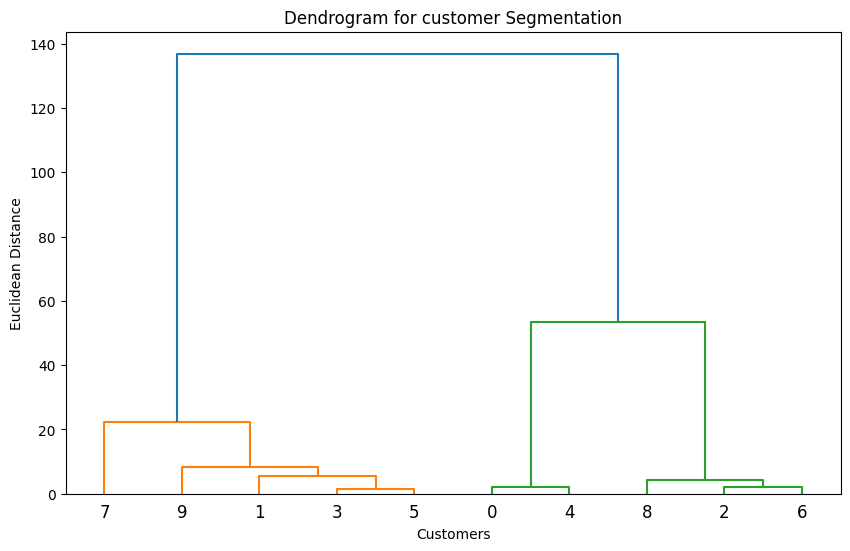

In [30]:
# Step 3 : Create a  Dendrogram to find optimal clusters
plt.figure(figsize=(10,6))
dendrogram = sch.dendrogram(sch.linkage(x[:10],method='ward'))

plt.title('Dendrogram for customer Segmentation')
plt.xlabel('Customers')
plt.ylabel('Euclidean Distance')
plt.show()

In [31]:
# Step 4: Fit Agglomerative Hierarchical Clustering
hc = AgglomerativeClustering(n_clusters=5,linkage='ward')
y_hc= hc.fit_predict(x)


In [32]:
y_hc

array([4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3,
       4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 1,
       4, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 2, 0, 2, 0, 2,
       1, 2, 0, 2, 0, 2, 0, 2, 0, 2, 1, 2, 0, 2, 1, 2, 0, 2, 0, 2, 0, 2,
       0, 2, 0, 2, 0, 2, 1, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2,
       0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2,
       0, 2])

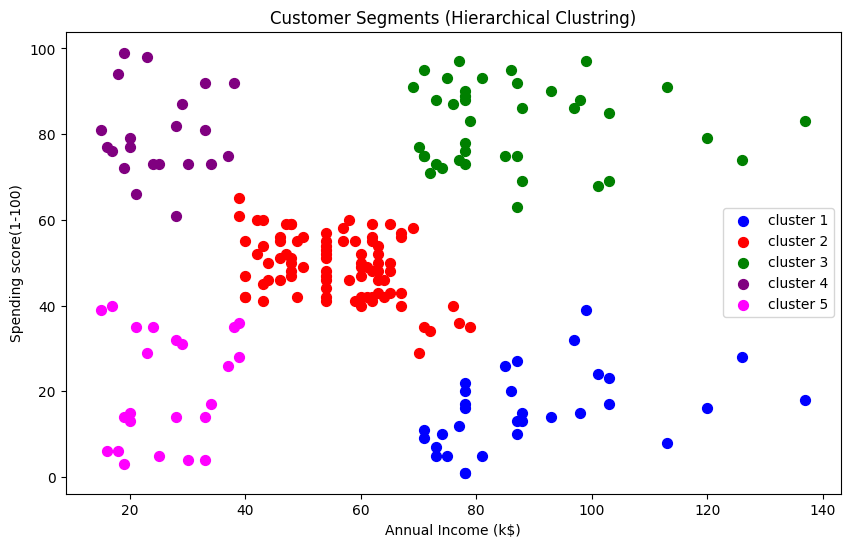

In [33]:
plt.figure(figsize=(10,6))
plt.scatter(x[y_hc ==0,0],x[y_hc==0,1],s=50,c='blue',label= 'cluster 1')
plt.scatter(x[y_hc ==1,0],x[y_hc==1,1],s=50,c='red',label= 'cluster 2')
plt.scatter(x[y_hc ==2,0],x[y_hc==2,1],s=50,c='green',label= 'cluster 3')
plt.scatter(x[y_hc ==3,0],x[y_hc==3,1],s=50,c='purple',label= 'cluster 4')
plt.scatter(x[y_hc ==4,0],x[y_hc==4,1],s=50,c='magenta',label= 'cluster 5')

plt.title('Customer Segments (Hierarchical Clustring)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending score(1-100)')
plt.legend()
plt.show()

## **Model Evaluation**

In [34]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
x = data[['Annual Income (k$)','Spending Score (1-100)']]
# Compute silhouette 
score = silhouette_score(x,y_hc)
print("silhouette score: ",round(score,3))

silhouette score:  0.553


In [35]:
# Observation 
# We can see Clustering is very much upto and clear
# Silhouette Score is 0.55 which is quite acceptable